# PRIMs in Jupyter

`pyprims.notebook` gives a notebook the functionality of the Swift PRIMs interface:

| Swift GUI | notebook |
|---|---|
| Load | `s.load(path)` (`.prims` or `.py`), `s.load(text)`, `s.load(task)`, or a `%%prims` / `%%pyprims` cell |
| Step | `s.step()` (one half step: an operator, or the module actions after it); `s.step_operator()` |
| Run / Run 10 / Run 100 / Stop | `s.run(n)`; `s.stop()` from the dashboard |
| Reset / Clear All | `s.reset()`, `s.clear()` |
| Trace with detail levels 1–5 | `s.trace(level)`, `s.show_trace(level)` |
| Task list | `s.tasks()`, `s.select_task(name)` |
| Buffers | `s.buffers()` |
| Declarative memory | `s.dm()`, `s.chunk(name)` |
| Conflict trace | `s.conflict_set()` |
| Chart: model results / operator activations | `s.plot_results()`, `s.plot_operator_activations()` |
| PRIMs graph (two levels) | `s.plot_graph(1)`, `s.plot_graph(2)`, plus `"productions"` and `"dm"` |
| Batch run | `s.batch(file)`, `plot_batch(...)` |
| The whole window | `Dashboard(s)` |

Plots are shown as PNG images and do not depend on the matplotlib backend; use `with figure(rows, cols) as axes:` to put several in one figure.

Stepping and looking never change what the model does: a seeded model gives the same results whether it is stepped and inspected or simply run.

This notebook sits in the `examples` folder, next to the models it uses.

In [2]:
from pyprims.notebook import Session, Dashboard, figure, plot_batch, read_batch
from pyprims import Task

## 1. Load a model and step through a trial

In [4]:
s = Session(seed=1)
s.load("count.prims")
s.tasks()

,task,state,format,source
,count ●,loaded,prims,count.prims


One `step()` is one half step, as with the Swift Step button. The first selects and executes an operator:

In [6]:
s.step()
s.buffers()

Operator
  start-count
  Conditions: V1<>nil WM1=nil
  Actions: V1->WM1 C1->RT1 V1->RT2 C2->AC1 V1->AC2
  Constants:
  C1 count-fact
  C2 say
Input
  V1 three
  V2 four
Goal
  G0 currentGoalChunk0
  G1 count
New imaginal
  WM0 imaginal4
  WM1 three

The next step does the module actions (here the retrieval of the next count fact and the `say` action):

In [8]:
s.step()
s.buffers()

Operator
  start-count
  Conditions: V1<>nil WM1=nil
  Actions: V1->WM1 C1->RT1 V1->RT2 C2->AC1 V1->AC2
  Constants:
  C1 count-fact
  C2 say
Input
  V1 three
  V2 four
Action
  AC1 say
  AC2 three
Goal
  G0 currentGoalChunk0
  G1 count
Retrieval request
  RT0 retrievalR5
  RT1 count-fact
  RT2 three
New harvest
  RT0 cf3
  RT1 count-fact
  RT2 three
  RT3 four
New imaginal
  WM0 imaginal4
  WM1 three

In [9]:
print(s.trace(3))      # levels: 1 operators, 2 + modules, 3 + productions, 4 + compilation, 5 all

Counting from three to four 
0.00  Starting new trial
0.00  *** Retrieved operator start-count with latency 0.001
0.00  Firing V1<>nil
0.05  Firing WM1=nil
0.35  Firing V1->WM1
0.65  Firing C1->RT1
0.95  Firing V1->RT2
1.25  Firing C2->AC1
1.55  Firing V1->AC2
1.85  Retrieving cf3 (latency = 0.049)
1.85  Saying three  (latency = 0.339)


The conflict set of the last retrieval, best first. Click a name to see how its activation is made up.
While stepping, the breakdown is taken at the moment of retrieval, so it adds up to the activation the model used.

In [11]:
s.step_operator()       # steps until an operator and its module actions are done
s.step()                # the next operator: its selection is the last retrieval
s.conflict_set()

final                             5.870  <- selected
iterate                           4.461

In [12]:
s.chunk("cf3")          # one chunk: slots, activation breakdown, associations

cf3
  isa  fact
  slot1  count-fact
  slot2  three
  slot3  four

Total activation = 1.688
Baselevel activation = 1.478  (fixed 1.000, refs 2)
Current noise = 0.210
Total spreading activation = 0.000

Spreading activation calculation
Spreading from goal buffer, spreading parameter = 1.000

## 2. Run, and plot results

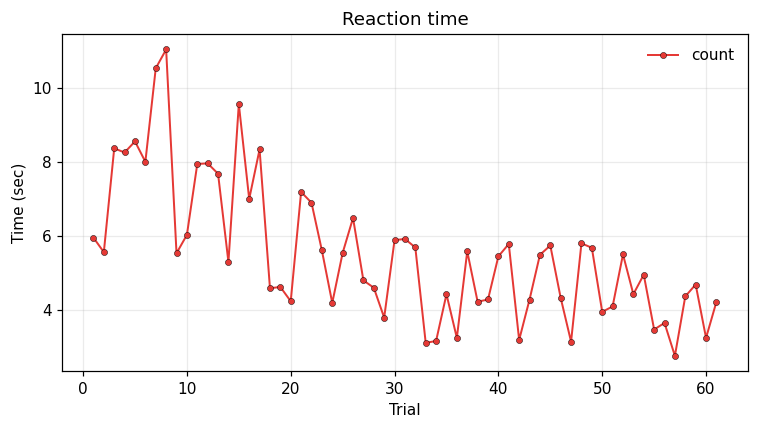

In [14]:
s.run(1)                # finishes the trial under way
s.run(60)
ax = s.plot_results()

In [15]:
s.dm().head(10)         # declarative memory, sorted by activation (a pandas DataFrame)

,type,activation,base_level,spreading,references,fan,slots
name,,,,,,,
iterate,operator,4.282071,1.039198,3.0,1,0,slot1=count-fact slot2=say condition=WM1=RT2;V...
count,goaltype,4.255734,1.039198,3.0,1,0,slot1=count
final,operator,3.781573,1.039198,3.0,1,0,slot1=say slot2=stop condition=V2=WM1 action=C...
start-count,operator,3.543976,1.039198,3.0,1,0,slot1=count-fact slot2=say condition=V1<>nil;W...
cf2,fact,2.637629,2.014861,0.0,44,0,slot1=count-fact slot2=two slot3=three
cf3,fact,2.343139,2.175173,0.0,56,0,slot1=count-fact slot2=three slot3=four
cf5,fact,1.999568,1.672661,0.0,24,0,slot1=count-fact slot2=five slot3=six
four,fact,1.958151,1.565064,0.0,19,2,slot1=four
cf4,fact,1.837313,1.985454,0.0,42,0,slot1=count-fact slot2=four slot3=five


In [16]:
s.productions().head(10)

,name,utility,size,above_primU,task,remaining,parents
0,C2->AC1;RT3->AC2,3.690845,2,True,count,,
1,C2->AC2;nil->G1,3.648281,2,True,count,,
2,V2=WM1;C1->AC1,3.581913,2,True,count,C2->AC2;nil->G1,
3,RT3->RT2;C2->AC1;RT3->AC2,3.420808,3,True,count,,C2->AC1;RT3->AC2
4,WM1=RT2;V2<>WM1;RT3->WM1;C1->RT1,3.404686,4,True,count,RT3->RT2;C2->AC1;RT3->AC2,WM1=RT2;V2<>WM1 + RT3->WM1;C1->RT1
5,RT3->RT2;C2->AC1,3.379466,2,True,count,RT3->AC2,
6,C1->RT1;RT3->RT2,3.359267,2,True,count,C2->AC1;RT3->AC2,
7,V1->RT2;C2->AC1,3.341109,2,True,count,V1->AC2,
8,V2=WM1;C1->AC1;C2->AC2;nil->G1,3.268314,4,True,count,,V2=WM1;C1->AC1 + C2->AC2;nil->G1
9,C1->RT1;RT3->RT2;C2->AC1;RT3->AC2,3.108604,4,True,count,,C1->RT1;RT3->RT2 + C2->AC1;RT3->AC2


## 3. The PRIMs graph

Level 1 shows tasks, skills and operators; level 2 adds the PRIMs of each operator. Operators that share a sequence of PRIMs share nodes. Colours mark the task that defined a node, a yellow halo marks a node used by more than one task, and red edges are learned skill–operator associations.

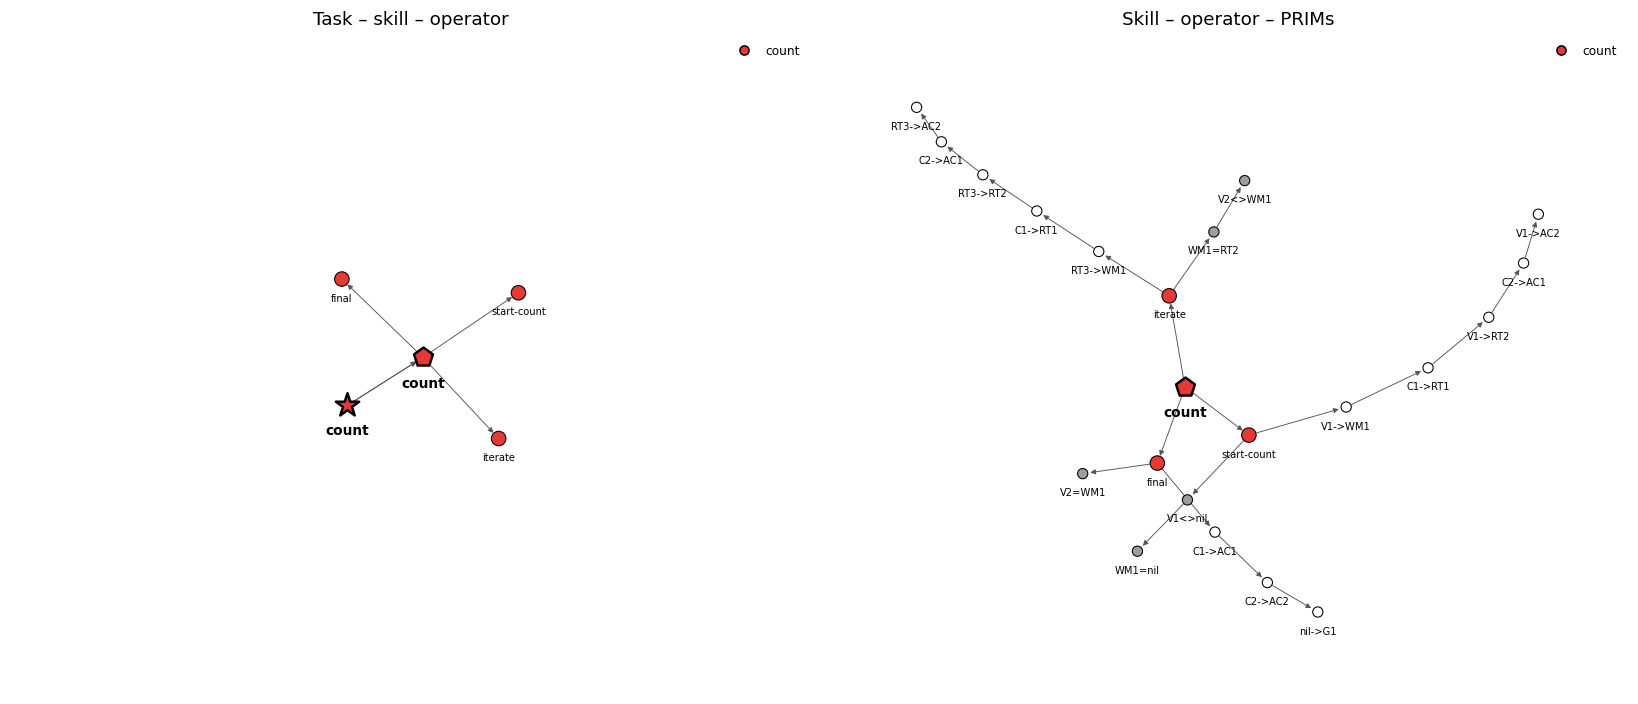

In [18]:
with figure(1, 2, figsize=(15, 6.5)) as axes:      # several plots in one figure
    s.plot_graph(1, ax=axes[0], seed=1)
    s.plot_graph(2, ax=axes[1], seed=1)

## 4. Transfer: a second task in the same model

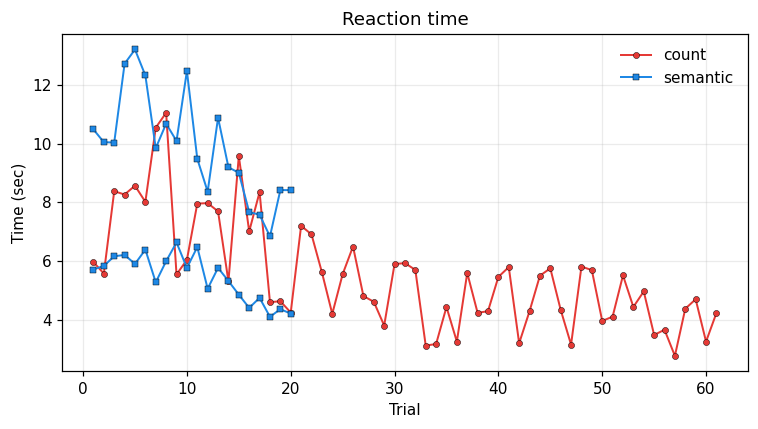

In [20]:
s.load("semantic.prims")     # adds a task: DM and learned productions carry over
s.run(20)
s.reset()                    # a fresh model with only semantic: the control condition
s.run(20)
ax = s.plot_results()        # one line per run of a task, coloured by task

In [21]:
s.select_task("count")       # Swift: click a task in the task list
s.tasks()

,task,state,format,source
,count ●,loaded,prims,count.prims
,semantic,loaded,prims,semantic.prims


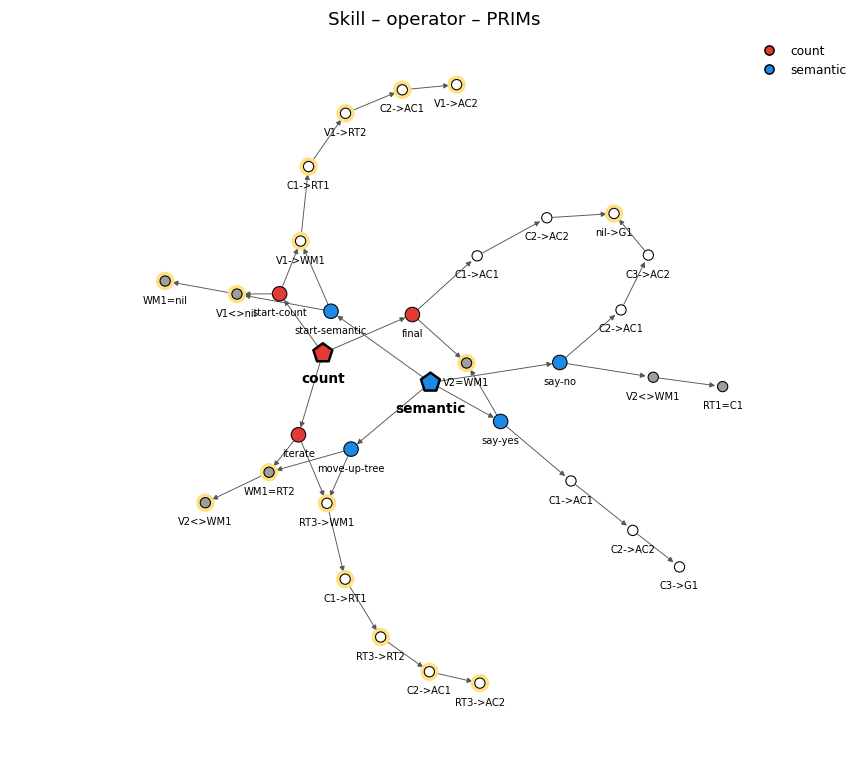

In [22]:
s2 = Session(seed=4)
s2.load("count.prims"); s2.run(40)
s2.load("semantic.prims"); s2.run(5)
ax = s2.plot_graph(2, seed=3)         # halos: PRIM sequences shared by count and semantic

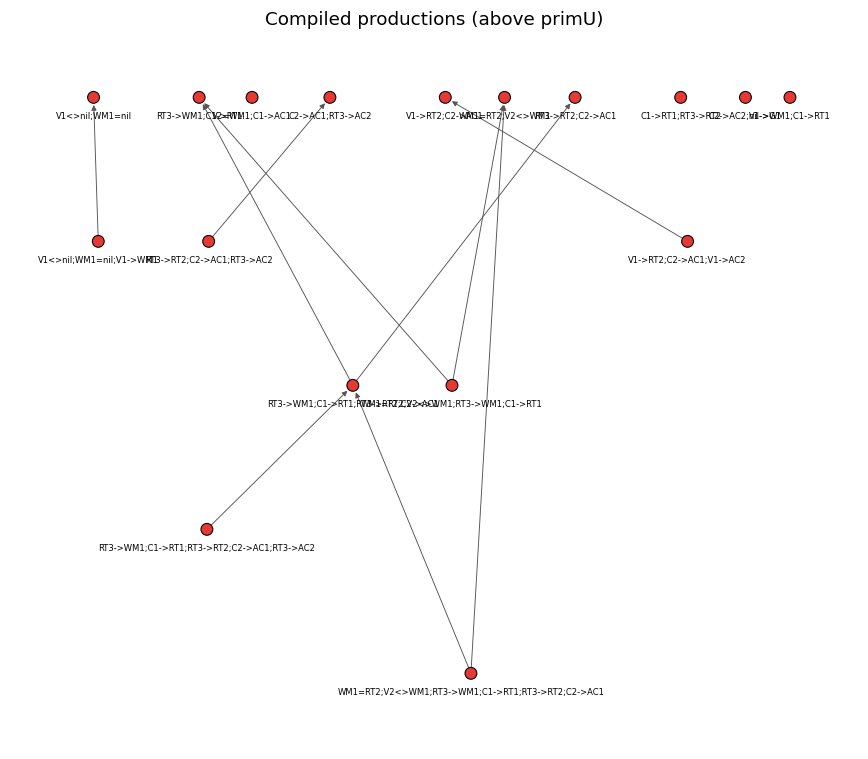

In [23]:
ax = s2.plot_graph("productions", seed=1)     # compiled productions above primU, by size

## 5. Writing models in cells: standard PRIMs or Python PRIMs

`%%prims` takes a cell in standard PRIMs syntax; `%%pyprims` takes a cell that builds a `Task` with the Python API.
Both load into the session named after the magic (default `session`). Re-running a cell after an edit redefines the task and resets the model.

In [25]:
%%prims counting --reset
define task count {
  initial-skills: (count)
  default-activation: 1.0
  ol: t
  rt: -2.0
  lf: 0.2
  default-operator-self-assoc: 0.0
  egs: 0.05
  retrieval-reinforces: t
}

define skill count {
  operator start-count {
   V1 <> nil
   WM1 = nil
  ==>
   V1 -> WM1
   count-fact -> RT1
   V1 -> RT2
   say -> AC1
   V1 -> AC2
  }
  operator iterate {
    RT2 = WM1
    V2 <> WM1
   ==>
    RT3 -> WM1
    count-fact -> RT1
    RT3 -> RT2
    say -> AC1
    RT3 -> AC2
  }
  operator final {
    V2 = WM1
   ==>
    say -> AC1
    stop -> AC2
    nil -> G1
  }
}

define facts {
    (cf1 count-fact one two)
    (cf2 count-fact two three)
    (cf3 count-fact three four)
    (cf4 count-fact four five)
    (cf5 count-fact five six)
}

define action say {
  latency: 0.3
  noise: 0.1
  distribution: uniform
  output: Saying
}

define script {
    digits = ["one","two","three","four","five","six"]
    start = random(3)
    end = start + 1 + random(2)
    print("Counting from",digits[start],"to",digits[end])
    screen(digits[start],digits[end])
    run-until-action("say","stop")
    issue-reward()
    trial-end()
}

Loaded task 'count' into counting (tasks: count)


In [26]:
counting.run(30)
print(counting.to_python()[:900])      # the same model in Python syntax

"""PRIMs model converted from model.prims by pyprims.convert."""
from pyprims import Task

task = Task('count',
            initial_skills=['count'],
            default_activation=1.0,
            ol=True,
            rt=-2.0,
            lf=0.2,
            default_operator_self_assoc=0.0,
            egs=0.05,
            retrieval_reinforces=True)

skill_count = task.skill('count')
skill_count.operator('start-count', '''
         V1 <> nil
         WM1 = nil
        ==>
         V1 -> WM1
         count-fact -> RT1
         V1 -> RT2
         say -> AC1
         V1 -> AC2
    ''')
skill_count.operator('iterate', '''
         RT2 = WM1
         V2 <> WM1
        ==>
         RT3 -> WM1
         count-fact -> RT1
         RT3 -> RT2
         say -> AC1
         RT3 -> AC2
    ''')
skill_count.operator('final', '''
         V2 = WM1
        ==>
         say -> AC1
         stop -> AC2
 


In [27]:
%%pyprims counting
task = Task("count-down", initial_skills=["count-down"], default_activation=1.0, ol=True,
            rt=-2.0, lf=0.2, default_operator_self_assoc=0.0, egs=0.05, retrieval_reinforces=True)

down = task.skill("count-down")
down.operator("start", """
    V1 <> nil
    WM1 = nil
==>
    V1 -> WM1
    count-fact -> RT1
    V1 -> RT3          // retrieve the fact that ends in the current number
    say -> AC1
    V1 -> AC2
""")
down.operator("iterate", """
    RT3 = WM1
    V2 <> WM1
==>
    RT2 -> WM1
    count-fact -> RT1
    RT2 -> RT3
    say -> AC1
    RT2 -> AC2
""")
down.operator("final", """
    V2 = WM1
==>
    say -> AC1
    stop -> AC2
    nil -> G1
""")
task.action("say", latency=0.3, noise=0.1, distribution="uniform", output="Saying")

@task.script
def script(m):
    digits = ["one", "two", "three", "four", "five", "six"]
    start = 2 + m.random(4)
    end = start - 1 - m.random(2)
    m.print("Counting down from", digits[start], "to", digits[end])
    m.screen(digits[start], digits[end])
    m.run_until_action("say", "stop")
    m.issue_reward()
    m.trial_end()

Loaded task 'count-down' into counting (tasks: count, count-down)


`count-down` has no facts of its own: it uses the count facts that `count` put in declarative memory, and the productions `count` compiled.

In [29]:
counting.run(30)
counting.tasks()

,task,state,format,source
,count,loaded,prims,<text>
,count-down ●,loaded,python,<cell>


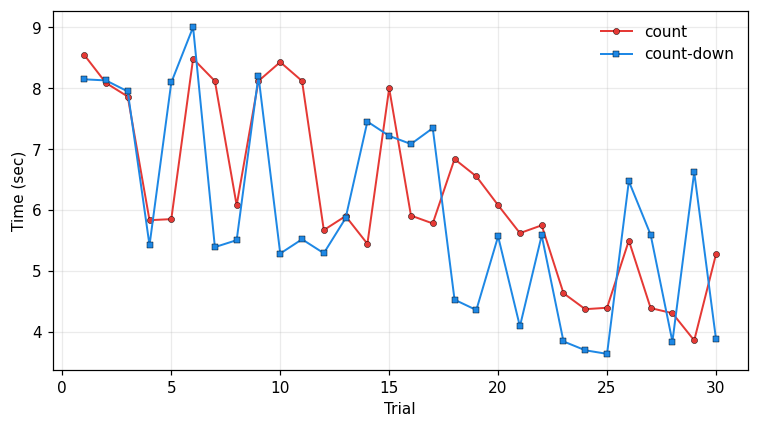

In [30]:
ax = counting.plot_results()

In [31]:
counting.step(4)
print(counting.trace(2))

Counting down from five to four 
366.67  Starting new trial
366.68  *** Retrieved operator start with latency 0.005
367.93  Retrieving cf4 (latency = 0.022)
367.93  Saying five  (latency = 0.267)
368.20  *** Retrieved operator iterate702 with latency 0.003
369.45  Retrieving cf3 (latency = 0.032)
369.45  Saying four  (latency = 0.371)


## 6. Operator activations within a trial

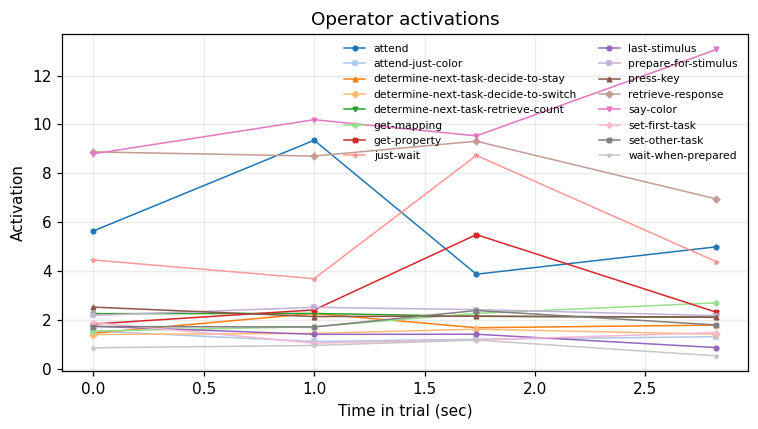

In [33]:
t = Session(seed=2)
t.load("task-switching.prims")
t.run(10)
t.load("stroop.prims")
t.track_operator_activations = True      # recorded at every operator step of a trial
t.run(4)
ax = t.plot_operator_activations()

## 7. Batch runs

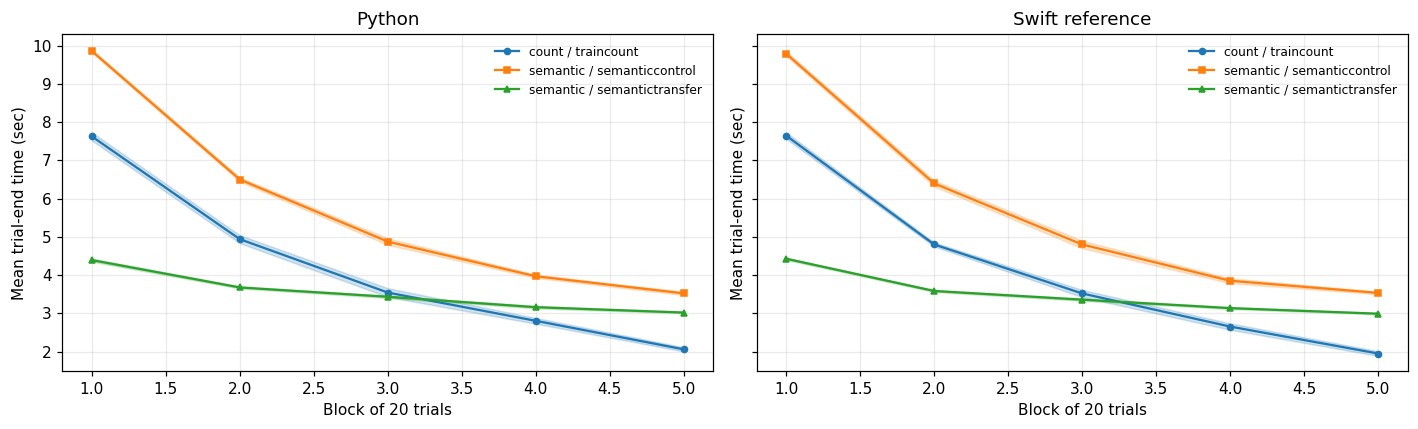

In [35]:
out = s.batch("testbatch.bprims", seed=1)           # 10 runs of count -> semantic, and a semantic control
with figure(1, 2, figsize=(13, 4), sharey=True) as axes:
    plot_batch(out, ax=axes[0], block=20).set_title("Python")
    plot_batch("swift_reference/testbatch.dat.gz", ax=axes[1], block=20).set_title("Swift reference")

## 8. The dashboard

All of the above as one widget, laid out like the Swift window (needs `ipywidgets`). The buttons act on the same session, so you can switch between the dashboard and code cells.

In [37]:
Dashboard(s)